<a href="https://colab.research.google.com/github/MilaniS-sudo/ASR700-Robotics-Assignment/blob/main/component_a/question3/pid_controller.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Controller correction: 3.02


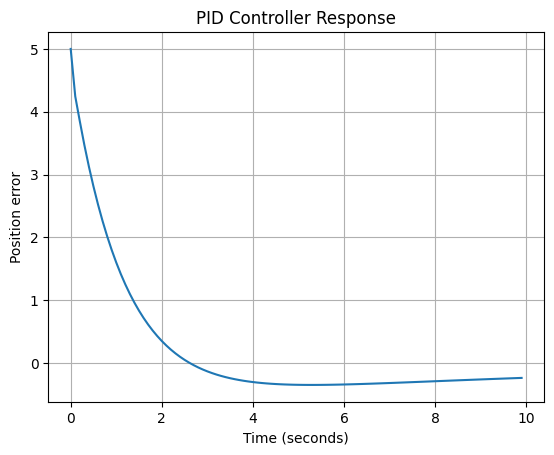

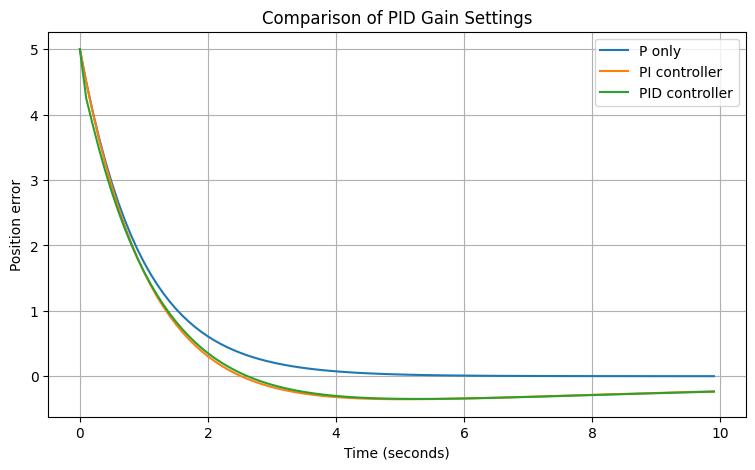

In [1]:

class PIDController:
    def __init__(self, kp, ki, kd):
        self.kp = kp
        self.ki = ki
        self.kd = kd
        self.integral = 0.0
        self.previous_error = 0.0

    def update(self, error, dt):
        if dt <= 0:
            raise ValueError("dt must be greater than zero")

        self.integral += error * dt
        derivative = (
            error - self.previous_error
        ) / dt

        output = (
            self.kp * error
            + self.ki * self.integral
            + self.kd * derivative
        )

        self.previous_error = error
        return output


# Simple test
pid = PIDController(kp=1.0, ki=0.1, kd=0.05)
correction = pid.update(error=2.0, dt=0.1)

print("Controller correction:", correction)

import matplotlib.pyplot as plt

# Simulation settings
dt = 0.1
time_values = []
error_values = []

# Create the controller
pid = PIDController(kp=1.0, ki=0.1, kd=0.05)

# Initial error
error = 5.0
position = 0.0
target = 5.0

for step in range(100):
    current_time = step * dt

    error = target - position
    correction = pid.update(error, dt)

    # Simplified system: correction changes position
    position += correction * dt

    time_values.append(current_time)
    error_values.append(error)

plt.plot(time_values, error_values)
plt.xlabel("Time (seconds)")
plt.ylabel("Position error")
plt.title("PID Controller Response")
plt.grid(True)
plt.show()

import matplotlib.pyplot as plt

gain_settings = [
    (1.0, 0.0, 0.0, "P only"),
    (1.0, 0.1, 0.0, "PI controller"),
    (1.0, 0.1, 0.05, "PID controller")
]

plt.figure(figsize=(9, 5))

for kp, ki, kd, label in gain_settings:
    pid = PIDController(kp, ki, kd)
    position = 0.0
    target = 5.0
    errors = []

    for step in range(100):
        error = target - position
        correction = pid.update(error, 0.1)
        position += correction * 0.1
        errors.append(error)

    plt.plot(
        [step * 0.1 for step in range(100)],
        errors,
        label=label
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Position error")
plt.title("Comparison of PID Gain Settings")
plt.legend()
plt.grid(True)
plt.show()


PID Controller Performance Analysis

The Proportional-Integral-Derivative (PID) controller adjusts the system’s response based on the current error, accumulated error, and rate of change of error.

* Proportional gain (Kp): Responds to the current error. Increasing it can improve response speed but may cause overshoot or instability.
* Integral gain (Ki): Accumulates error over time and can reduce steady-state error.
* Derivative gain (Kd): Responds to changes in error and can help reduce overshoot and improve damping.

Performance measures:

* Rise time: Time taken for the response to approach its target.
* Overshoot: How far the response goes beyond its target.
* Settling time: Time taken for the response to remain close to its target.
* Steady-state error: Remaining difference between the target and the final response.

The current results come from a simplified simulation. Further testing with a robot model in Webots is required to evaluate realistic path tracking and control performance.